# Module 04: Linear Systems, Rank and Inverses

"Solve Ax = b" asks: **which input x does the transformation A send to b?** Sometimes there is exactly one answer,
sometimes infinitely many, sometimes none. Which case you're in depends on the **rank** of A. That idea explains
multicollinearity, why some regressions blow up, and what "degrees of freedom" really means.

**Learning goals**
- Three pictures of Ax = b: intersecting rows, combining columns, undoing a transformation
- Gaussian elimination by hand and in code
- Linear independence, basis, dimension, rank; column space and null space
- The determinant as an area/volume scale factor
- Inverses, and why you should use `np.linalg.solve` instead of `inv`
- Near-singular matrices and the condition number

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. Three pictures of the same system
$$\begin{aligned} 2x + y &= 5 \\ x - y &= 1 \end{aligned} \quad\Longleftrightarrow\quad
\underbrace{\begin{pmatrix}2 & 1\\1 & -1\end{pmatrix}}_{A}\begin{pmatrix}x\\y\end{pmatrix} = \begin{pmatrix}5\\1\end{pmatrix}$$

1. **Row picture:** each equation is a line, and the solution is where the lines cross.
2. **Column picture:** find weights x, y so that $x\,\text{col}_1 + y\,\text{col}_2 = \mathbf{b}$.
3. **Transformation picture:** find the vector that A moves onto b.

solution: [2. 1.]


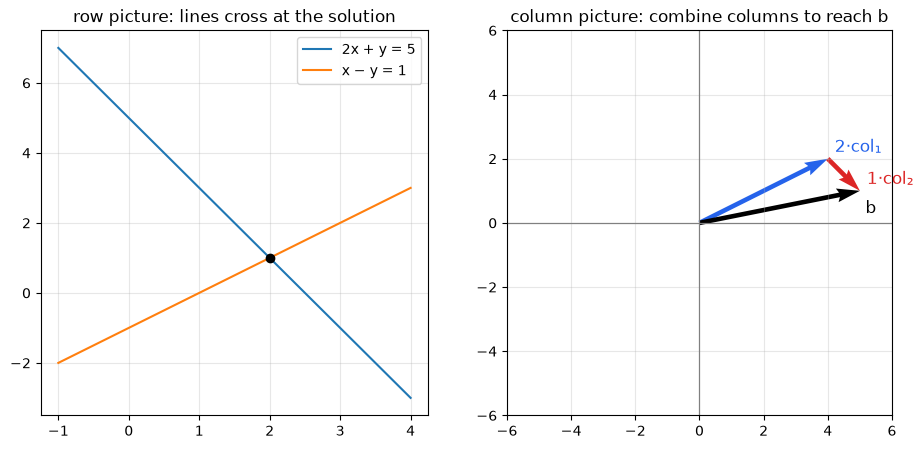

In [2]:
A = np.array([[2.0, 1.0], [1.0, -1.0]])
b = np.array([5.0, 1.0])
sol = np.linalg.solve(A, b)
print("solution:", sol)

fig, axs = plt.subplots(1, 2, figsize=(11, 5))
xs = np.linspace(-1, 4, 10)
axs[0].plot(xs, 5 - 2 * xs, label="2x + y = 5")
axs[0].plot(xs, xs - 1, label="x − y = 1")
axs[0].plot(*sol, "ko"); axs[0].set_title("row picture: lines cross at the solution")
axs[0].legend(); axs[0].grid(alpha=0.3)
c1, c2 = A[:, 0], A[:, 1]
mplt.plot_vectors([sol[0] * c1, sol[1] * c2], origin=[[0, 0], sol[0] * c1], labels=[f"{sol[0]:.0f}·col₁", f"{sol[1]:.0f}·col₂"],
                  ax=axs[1], lim=6, title="column picture: combine columns to reach b")
mplt.plot_vectors([b], ax=axs[1], lim=6, colors=["k"])
axs[1].annotate("b", b, textcoords="offset points", xytext=(4, -16), fontsize=12)
plt.show()

## 2. Gaussian elimination
The by-hand algorithm: use row operations to make the system **upper triangular**, then **back-substitute**.
Row operations (add a multiple of one row to another, swap rows, scale a row) never change the solution.

$$\left(\begin{array}{cc|c} 2 & 1 & 5\\ 1 & -1 & 1\end{array}\right)
\xrightarrow{R_2 \leftarrow R_2 - \tfrac12 R_1}
\left(\begin{array}{cc|c} 2 & 1 & 5\\ 0 & -1.5 & -1.5\end{array}\right)$$
Back-substitute: $y = 1$, then $2x + 1 = 5 \Rightarrow x = 2$.

Below is the algorithm in code, with **partial pivoting** (swap in the row with the biggest pivot, which keeps
rounding errors small).

In [3]:
def gaussian_elimination(A, b):
    A = A.astype(float).copy()
    b = b.astype(float).copy()
    n = len(b)
    for k in range(n):
        p = k + np.argmax(np.abs(A[k:, k]))          # pivot row: biggest entry in this column
        A[[k, p]], b[[k, p]] = A[[p, k]], b[[p, k]]  # swap rows
        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor * A[k, k:]            # eliminate entry (i, k)
            b[i] -= factor * b[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                   # back substitution, bottom row first
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

M = rng.normal(size=(5, 5)); rhs = rng.normal(size=5)
print(np.allclose(gaussian_elimination(M, rhs), np.linalg.solve(M, rhs)))

True


## 3. Linear independence, basis and rank
Vectors are **linearly independent** if none of them is a combination of the others. Equivalently, the only way to
make $c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k = \mathbf{0}$ is all $c_i = 0$.

- A **basis** of a space is an independent set that spans it. The **dimension** is how many vectors that takes.
- The **rank** of A is the number of independent columns, which is the dimension of the space A's outputs fill.
- The **column space** $C(A)$ is all reachable outputs Ax (the span of the columns).
- The **null space** $N(A)$ is all inputs that get crushed to zero: $A\mathbf{x} = \mathbf{0}$.

**Rank–nullity:** for A with n columns, $\text{rank}(A) + \dim N(A) = n$. Every dimension either survives into the
output or gets crushed.

In [4]:
full = np.array([[1, 2, 0], [0, 1, 1], [1, 0, 3]], dtype=float)
deficient = np.array([[1, 2, 3], [2, 4, 6], [1, 0, 1]], dtype=float)     # row 2 = 2 × row 1
for name, Mx in [("full", full), ("deficient", deficient)]:
    print(f"{name}: rank = {np.linalg.matrix_rank(Mx)}")

from scipy.linalg import null_space
ns = null_space(deficient)
print("null space basis of the deficient matrix:\n", ns.round(4).ravel())
print("A @ null vector =", (deficient @ ns).round(10).ravel())

full: rank = 3
deficient: rank = 2
null space basis of the deficient matrix:
 [-0.5774 -0.5774  0.5774]
A @ null vector = [0. 0. 0.]


### What rank means for Ax = b
| situation | solutions |
|---|---|
| A square, full rank | exactly one: $\mathbf{x} = A^{-1}\mathbf{b}$ |
| b not in the column space | **none** (the best you can do is least squares, module 05) |
| b in C(A), but N(A) is non-trivial | **infinitely many**: any solution plus any null-space vector |

**ML link: multicollinearity.** If one feature is a combination of others (e.g. `total = a + b` included alongside
a and b), then $X$ loses rank, $X^\top X$ isn't invertible, and linear-regression weights are not unique. You can
shift weight along the null-space direction without changing a single prediction.

In [5]:
n = 100
f1, f2 = rng.normal(size=n), rng.normal(size=n)
X = np.column_stack([f1, f2, f1 + f2])             # third feature is redundant
print("rank of X:", np.linalg.matrix_rank(X), "out of", X.shape[1], "columns")
w1 = np.array([1.0, 2.0, 0.0])
w2 = w1 + 5 * np.array([1.0, 1.0, -1.0])           # (1, 1, −1) is in the null space of X
print("same predictions with different weights?", np.allclose(X @ w1, X @ w2))

rank of X: 2 out of 3 columns
same predictions with different weights? True


## 4. The determinant: how much area gets scaled
For a 2×2 matrix, $\det\begin{pmatrix}a & b\\c & d\end{pmatrix} = ad - bc$. Geometrically, it is the factor by which A
scales areas (volumes in 3-D). Its sign tells you whether orientation is flipped.
- $\det = 0$: space is squashed flat, so A is **singular** (not invertible).
- $\det(AB) = \det(A)\det(B)$: scale factors multiply.
- $\lvert\det\rvert$ of a rotation is 1.

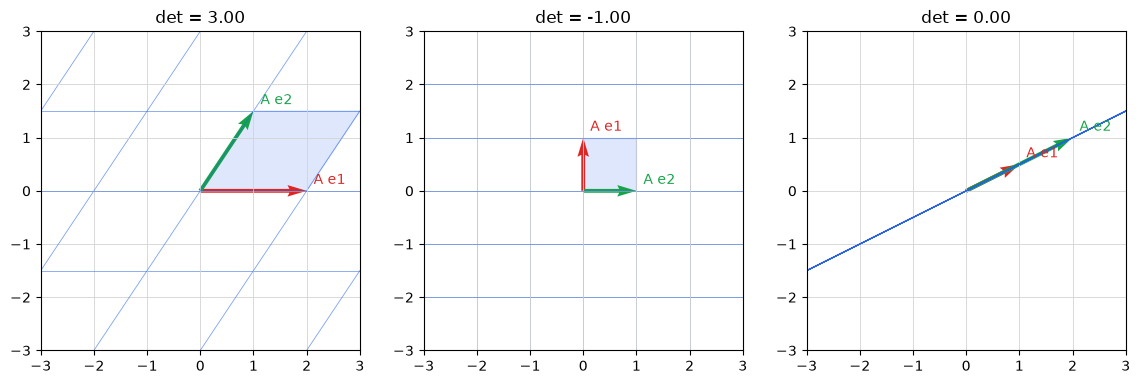

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, Mx in zip(axs, [np.array([[2, 1], [0, 1.5]]), np.array([[0, 1], [1, 0]]), np.array([[1, 2], [0.5, 1]])]):
    mplt.plot_linear_transform(Mx, ax=ax, lim=3, title=f"det = {np.linalg.det(Mx):.2f}")
plt.show()

The determinant shows up later in the multivariate Gaussian density (module 16) and in the change-of-variables
formula behind normalizing flows. **Don't** use it to test whether a matrix is "nearly singular": `det` of
`0.1 * np.eye(100)` is 1e-100, yet that matrix is perfectly well behaved. Use the condition number (section 6).

In [7]:
print(np.linalg.det(0.1 * np.eye(100)), np.linalg.cond(0.1 * np.eye(100)))

1.00000000000033e-100 1.0


## 5. Inverses
$A^{-1}$ undoes A: $A^{-1}A = AA^{-1} = I$. It exists exactly when A is square and full rank (det ≠ 0).
For 2×2: $\begin{pmatrix}a & b\\c & d\end{pmatrix}^{-1} = \frac{1}{ad-bc}\begin{pmatrix}d & -b\\-c & a\end{pmatrix}$.

Rules: $(AB)^{-1} = B^{-1}A^{-1}$ (undo in reverse order, like taking off socks and shoes) and
$(A^\top)^{-1} = (A^{-1})^\top$.

**In practice, don't compute `inv(A) @ b` to solve a system.** `np.linalg.solve` does one elimination (an LU
factorization) instead of building the whole inverse, so it is faster. It is also the numerically safer choice:
on a well-behaved matrix like the one below both residuals are tiny, but on ill-conditioned matrices `inv` loses
more accuracy. Keep `inv` for when you truly need the matrix $A^{-1}$ itself.

In [8]:
import time
big = rng.normal(size=(1500, 1500)); rhs = rng.normal(size=1500)
t0 = time.perf_counter(); x_inv = np.linalg.inv(big) @ rhs; t1 = time.perf_counter()
x_sol = np.linalg.solve(big, rhs); t2 = time.perf_counter()
print(f"inv: {t1 - t0:.3f}s   solve: {t2 - t1:.3f}s")
print("residual inv:  ", np.linalg.norm(big @ x_inv - rhs))
print("residual solve:", np.linalg.norm(big @ x_sol - rhs))

inv: 0.052s   solve: 0.017s
residual inv:   5.587319611823724e-09
residual solve: 9.963450697711985e-09


## 6. Near-singular matrices and the condition number
Real data is rarely *exactly* singular; it's **nearly** singular (two features 99.9% correlated). Then small noise in
b causes huge changes in x. The **condition number** $\kappa(A)$ measures this amplification: roughly, you lose
$\log_{10}\kappa$ digits of accuracy. κ ≈ 1 is great, and κ > 1e10 is trouble.

In [9]:
for eps in [1.0, 1e-3, 1e-8]:
    Mx = np.array([[1.0, 1.0], [1.0, 1.0 + eps]])
    x_clean = np.linalg.solve(Mx, np.array([2.0, 2.0 + eps]))
    x_noisy = np.linalg.solve(Mx, np.array([2.0, 2.0 + eps]) + np.array([0, 1e-6]))
    print(f"eps={eps:g}: cond={np.linalg.cond(Mx):.1e}  x={x_clean.round(3)}  x after 1e-6 noise={x_noisy.round(3)}")

eps=1: cond=6.9e+00  x=[1. 1.]  x after 1e-6 noise=[1. 1.]
eps=0.001: cond=4.0e+03  x=[1. 1.]  x after 1e-6 noise=[0.999 1.001]
eps=1e-08: cond=4.0e+08  x=[1. 1.]  x after 1e-6 noise=[-99. 101.]


That's why ridge regression adds $\lambda I$ to $X^\top X$: it pushes the smallest eigenvalue away from 0 and brings
the condition number down (more on this in modules 06–07).

## Where you'll use this
- **ML course:** 01 linear algebra (`solve`, multicollinearity), 07 linear regression (normal equation),
  09 Ridge (λI fixes conditioning).
- **DL course:** 16 VAEs and normalizing flows (determinants), 05 optimization (ill-conditioned loss surfaces).

## Summary
- Ax = b means intersecting lines (rows), combining columns, or undoing a transformation.
- Gaussian elimination, then back-substitution, is how solvers work. Pivot for stability.
- Rank = the number of independent columns. rank + nullity = the number of columns.
- det is the area scale factor. det = 0 means singular, but det is a poor measure of "nearly singular".
- Use `solve`, not `inv`. The condition number says how much noise gets amplified.

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [Inverse matrices, column space and null space (ch. 7)](https://www.3blue1brown.com/lessons/inverse-matrices) (3Blue1Brown). Rank and null space as pictures.
- ⭐ [The determinant (ch. 6)](https://www.3blue1brown.com/lessons/determinant) (3Blue1Brown). The determinant as an area scale factor.
- [Lecture 2: Elimination with Matrices](https://www.youtube.com/watch?v=QVKj3LADCnA) (Gilbert Strang, MIT 18.06). Elimination taught by the master.
- [Lecture 9: Independence, Basis, and Dimension](https://www.youtube.com/watch?v=yjBerM5jWsc) (Gilbert Strang, MIT 18.06).
- [Lecture 10: The Four Fundamental Subspaces](https://www.youtube.com/watch?v=nHlE7EgJFds) (Gilbert Strang, MIT 18.06). The 'big picture' of linear algebra.